# Pricing Engine: from shop data to price proposals

A walk through the project on the data of Lumo, a fictional online shop from [Data-Generator](https://github.com/tlabedzki/Data-Generator) v1.6.0 (seed 42). Run `python scripts/get_data.py` first.

1. Estimate how strongly demand reacts to price in each category and check it against the truth.
2. Propose a price for every product within the pricing rules, with a reason.
3. Simulate the yearly effect in three scenarios and with the true elasticity.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from pricing_engine import data, elasticity, engine, simulate, theme

pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 120)
shop = data.load()
print(f'{len(shop.products):,} products, {len(shop.orders):,} order lines, '
      f'{len(shop.competitor_prices):,} competitor price periods')

50,000 products, 80,326 order lines, 636,646 competitor price periods


## 1. Price elasticity per category

Elasticity 1.5 means a 1% higher price sells about 1.5% fewer units. Two signals carry it: list-price changes within a product (conditional Poisson, so product popularity cancels out) and discounts that add units to an order line (Poisson regression). Both are combined by precision and shrunk towards the average of all categories.

In [2]:
table = elasticity.estimate(shop)
low = table['elasticity'] - 1.645 * table['elasticity_se']
high = table['elasticity'] + 1.645 * table['elasticity_se']
table.assign(hit=(table['true_elasticity'] >= low) & (table['true_elasticity'] <= high))[
    ['category', 'list_price', 'discount', 'elasticity', 'elasticity_se', 'true_elasticity', 'hit']].round(2)

,category,list_price,discount,elasticity,elasticity_se,true_elasticity,hit
0,Automotive,1.40,1.03,1.13,0.19,1.2,True
1,Baby & Kids,1.13,0.69,0.77,0.15,0.8,True
2,Beauty,1.48,1.16,1.20,0.08,1.2,True
3,Books & Media,0.84,0.84,0.85,0.07,1.0,False
4,Clothing,1.77,1.82,1.81,0.04,1.8,True
5,DIY Tools,1.14,1.40,1.36,0.19,1.2,True
6,Electronics,1.93,1.84,1.83,0.12,1.6,False
7,Furniture,3.06,1.52,1.62,0.28,1.4,True
8,Health,0.20,0.54,0.47,0.07,0.6,False
9,Home & Garden,2.14,1.41,1.52,0.20,1.2,True


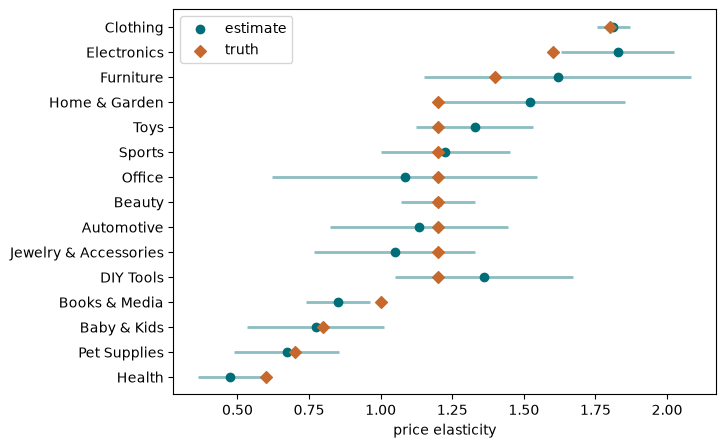

In [3]:
t = table.sort_values('true_elasticity')
fig, ax = plt.subplots(figsize=(7, 5))
ax.hlines(t['category'], t['elasticity'] - 1.645 * t['elasticity_se'], t['elasticity'] + 1.645 * t['elasticity_se'],
          color=theme.PRIMARY, alpha=0.45, linewidth=2)
ax.scatter(t['elasticity'], t['category'], color=theme.PRIMARY, label='estimate', zorder=3)
ax.scatter(t['true_elasticity'], t['category'], color=theme.ACCENT, marker='D', label='truth', zorder=4)
ax.set_xlabel('price elasticity')
ax.legend()
plt.show()

## 2. Price proposals

Rules of the base scenario: margin at least 15% after the average discount, at most 5% above the median competitor price, at most 10% up or down at once, prices ending in 9. Within them the engine picks the price with the highest expected gross profit.

In [4]:
snap = engine.snapshot(shop, table)
proposals = engine.propose(snap)
proposals[['action', 'binding']].value_counts().unstack(fill_value=0)

binding,margin_conflict,market_cap,market_conflict,profit_optimum,step_down,step_up
action,,,,,,
keep,6,4821,395,178,2045,1162
lower,0,7462,600,160,5154,0
raise,251,9219,989,155,0,10151


In [5]:
proposals.sample(8, random_state=7)[['product_name', 'current_price', 'proposed_price', 'competitor_median', 'reason']]

,product_name,current_price,proposed_price,competitor_median,reason
540,Mountain Bike Trek Marlin 5,4679.0,5009.0,4770.995,"Raise 7.1%: 1.9% below the competitor median; it stops at the limit of +5%, demand in Sports reacts strongly to pric..."
13158,Jeans H&M Regular Blue,689.0,739.0,703.990,"Raise 7.3%: 2.1% below the competitor median; it stops at the limit of +5%, demand in Clothing reacts strongly to pr..."
28282,Laptop Apple MacBook Pro 14,3049.0,3349.0,3219.490,"Raise 9.8%, as far as the 10% step limit allows: the margin is still below the minimum of 15%."
36821,Office Desk VOX Simple Desk,1549.0,1399.0,1322.990,"Lower 9.7%, as far as the 10% step limit allows: 17% above the competitor median, more than the limit of +5%."
39555,Smartphone Xiaomi Redmi Note 12,3079.0,3369.0,3328.490,"Raise 9.4%, as far as the 10% step limit allows: 7.5% below the competitor median, demand in Electronics reacts stro..."
27848,Mascara L'Oreal Telescopic Lift,309.0,279.0,241.990,"Lower 9.7%, as far as the 10% step limit allows: 28% above the competitor median, more than the limit of +5%."
6750,T-Shirt Sinsay Daily Classic,79.0,79.0,56.990,"Keep: 39% above the competitor median, more than the limit of +5%, but the next lower price ending in 9 is a bigger ..."
15030,Shampoo Nivea Care Shine,139.0,149.0,169.990,"Raise 7.2%, as far as the 10% step limit allows: 18% below the competitor median, demand in Beauty reacts strongly t..."


## 3. What the proposals do to a year of sales

The cautious scenario keeps prices at or below the competitor median, moves at most 5% and assumes demand 1.64 standard errors more sensitive; the bold one allows +10% over competitors and 15% steps. The last check judges the same proposals with the true elasticity from Data-Generator.

In [6]:
columns = ['scenario', 'profit_change', 'revenue_change', 'units_change', 'raise', 'lower', 'keep']
simulate.scenarios(snap)[columns].round(4)

,scenario,profit_change,revenue_change,units_change,raise,lower,keep
0,cautious,0.0064,0.0009,0.0055,13363.0,15542.0,13843.0
1,base,0.0300,-0.0061,-0.0043,20765.0,13376.0,8607.0
2,bold,0.0697,-0.0197,-0.0331,26728.0,9826.0,6194.0


In [7]:
truth = simulate.totals(simulate.evaluate(proposals, shop.true_elasticity())).iloc[0]
spread = simulate.uncertainty(proposals, table)
print(f"estimated {simulate.totals(proposals).iloc[0]['profit_change']:+.1%}, "
      f"90% interval {spread['profit_change'].quantile(0.05):+.1%} to {spread['profit_change'].quantile(0.95):+.1%}, "
      f"with the true elasticity {truth['profit_change']:+.1%}")

estimated +3.0%, 90% interval +2.9% to +3.1%, with the true elasticity +3.1%


In [8]:
by_category = simulate.totals(proposals, 'category')
by_category[['category', 'profit_change', 'revenue_change', 'raise', 'lower', 'keep']].sort_values(
    'profit_change', ascending=False).round(3)

,category,profit_change,revenue_change,raise,lower,keep
6,Electronics,0.201,-0.032,4961,1824,540
11,Office,0.084,-0.002,209,110,321
0,Automotive,0.081,-0.003,799,421,306
1,Baby & Kids,0.051,0.005,609,447,506
12,Pet Supplies,0.049,0.008,421,299,415
13,Sports,0.047,-0.004,1471,981,243
7,Furniture,0.029,-0.011,885,648,42
14,Toys,0.023,-0.005,765,513,287
9,Home & Garden,0.022,-0.004,2196,1447,308
5,DIY Tools,0.022,-0.003,615,373,164
